In [33]:
%matplotlib inline
!pip install opencv-python
!pip install PyMuPDF
!pip install matplotlib
!pip install pypdf
import matplotlib.pyplot as plt
import os
import cv2
import numpy as np
import fitz
from pypdf import PdfReader, PdfWriter
import time
import json
from IPython.display import IFrame

In [34]:
import sys
sys.path.append('../src')

from pdf_set import PDFSet

In [35]:
data = PDFSet.fromFolder('../case_outputs/yellow', 'fitz numpy300 ')

[TASK] Loading 0: ../case_outputs/yellow/50_SCHNEIDER TIMOTHY 74319531 2025 1 28.pdf into fitz done.
[TASK] Loading 1: ../case_outputs/yellow/37_ZAHM JONATHAN 08964556 2025 2 17.pdf into fitz done.
[TASK] Loading 2: ../case_outputs/yellow/40_SCIORROTTA CONGETTA 96903753 2025 3 27.pdf into fitz done.
[TASK] Loading 3: ../case_outputs/yellow/66_PORTNER TIMOTHY 21972819 2025 2 25.pdf into fitz done.
[TASK] Loading 4: ../case_outputs/yellow/16_PETERSEN KRISTINE 76163421 2025 4 18.pdf into fitz done.
[TASK] Loading 5: ../case_outputs/yellow/21_PARENZA MARY 67134451 2025 1 24.pdf into fitz done.
[TASK] Loading 6: ../case_outputs/yellow/87_PAVELEC VICKI 24357457 2025 4 29.pdf into fitz done.
[TASK] Loading 7: ../case_outputs/yellow/81_SCOTT THERESA 21321974 2025 1 21.pdf into fitz done.
[TASK] Loading 8: ../case_outputs/yellow/52_KLINK JUDITH 66604949 2025 5 8.pdf into fitz done.
[TASK] Loading 9: ../case_outputs/yellow/9_RINEHART CARRIE 97735165 2025 2 3.pdf into fitz done.
[TASK] Loading 10

[]


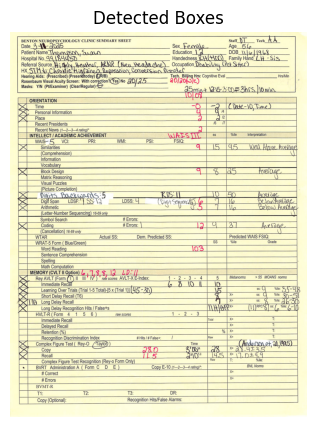

In [36]:
#### Follows grayscale -> blur -> threshold -> contour
n = 20
page, img, fn = data[n,0]
img = img.copy()

def rect_bound(approx) -> tuple[np.ndarray, int]:
    x, y, w, h = cv2.boundingRect(approx)
    box = np.array([
        [x, y],
        [x + w, y],
        [x + w, y + h],
        [x, y + h]
    ])
    return box, w*h

def para_bound(approx) -> tuple[np.ndarray, int]:
    rect = cv2.minAreaRect(approx)  # note: use the original contour, not approx
    box = cv2.boxPoints(rect)
    box = np.intp(box)
    (_, _), (w, h), _ = rect
    return box, w*h


# Reduce image channels
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img

# Reduce image noise
blur = cv2.GaussianBlur(gray, (5, 5), 0) 

# Define adaptive threshold to convert image to BW, adjust for light
thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                               cv2.THRESH_BINARY_INV, 15, 10)

# Find external contours, and compress information
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

anchor_boxes = []
valids = 0
for contour in contours:
    # Simplify contour shape to retrieve bounding polygon
    approx = cv2.approxPolyDP(contour, 0.0395 * cv2.arcLength(contour, True), True)
    if len(approx) == 4 and cv2.isContourConvex(approx):
        valids += 1
        box, area = para_bound(approx)
        if area > 10000:
            cv2.drawContours(img, [box], 0, (0, 255, 0), 3)
            anchor_boxes.append((box, area))

anchor_boxes.sort(key=lambda pair: pair[1])
print(anchor_boxes)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.title("Detected Boxes")
plt.show()


In [37]:
template = '../configs/template2025.json'

with open(template) as f:
    config = json.load(f)

"""
Notes:
Anchors should be ordered from ascending expected area. This is the current method to identify them
"""

config




{'format_id': '2025',
 'anchors': ['top_box', 'bottom_box'],
 'censor': [{'name': 'Patient Name',
   'parent': 'top_box',
   'topleft': [0.1093, 0.223],
   'bottomright': [0.5465, 0.3284]},
  {'name': 'DOB',
   'parent': 'top_box',
   'topleft': [0.7962, 0.223],
   'bottomright': [0.9456, 0.3284]}]}

In [38]:
anchors = config.get('anchors')
blackout_query = config.get('censor')

assert len(anchors) == len(anchor_boxes)

def pos (box: np.ndarray, rel):
    p, q = tuple(rel)
    # Assumed order, may be incorrect
    topleft_x, topleft_y = box[0]
    topright_x, topright_y = box[1]
    bottomright_x, bottomright_y = box[2]
    bottomleft_x, bottomleft_y = box[3]
    return (
        (1-p)*(1-q)*topleft_x+(1-q)*p*topright_x+p*q*bottomright_x+(1-p)*q*bottomleft_x,
        (1-p)*(1-q)*topleft_y+(1-q)*p*topright_y+p*q*bottomright_y+(1-p)*q*bottomleft_y
    )

for field in blackout_query:
    parent_name = field['parent']
    parent_idx = anchors.index(parent_name)
    assert parent_idx != -1
    box, _ = anchor_boxes[parent_idx]
    abs_x1, abs_y1 = pos(box, field['topleft'])
    abs_x2, abs_y2 = pos(box, field['bottomright'])
    # turn to fitz units
    a = 72/300
    print(abs_x1*a, abs_y1*a, abs_x2*a, abs_y2*a)
    redact_area = fitz.Rect(abs_x1*a, abs_y1*a, abs_x2*a, abs_y2*a)
    page.add_redact_annot(redact_area, fill=(0, 0, 0))
page.apply_redactions()
doc, _, _ = data[n]
doc.save("censored_output.pdf")
doc.close()


AssertionError: 